# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import MUMUCDDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [40]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/mumucd/",
    "imagery" : "all"
}
dataset = MUMUCDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 70


2026-03-09 08:48:56,340 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:48:56,547 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:48:56,746 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:48:56,930 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


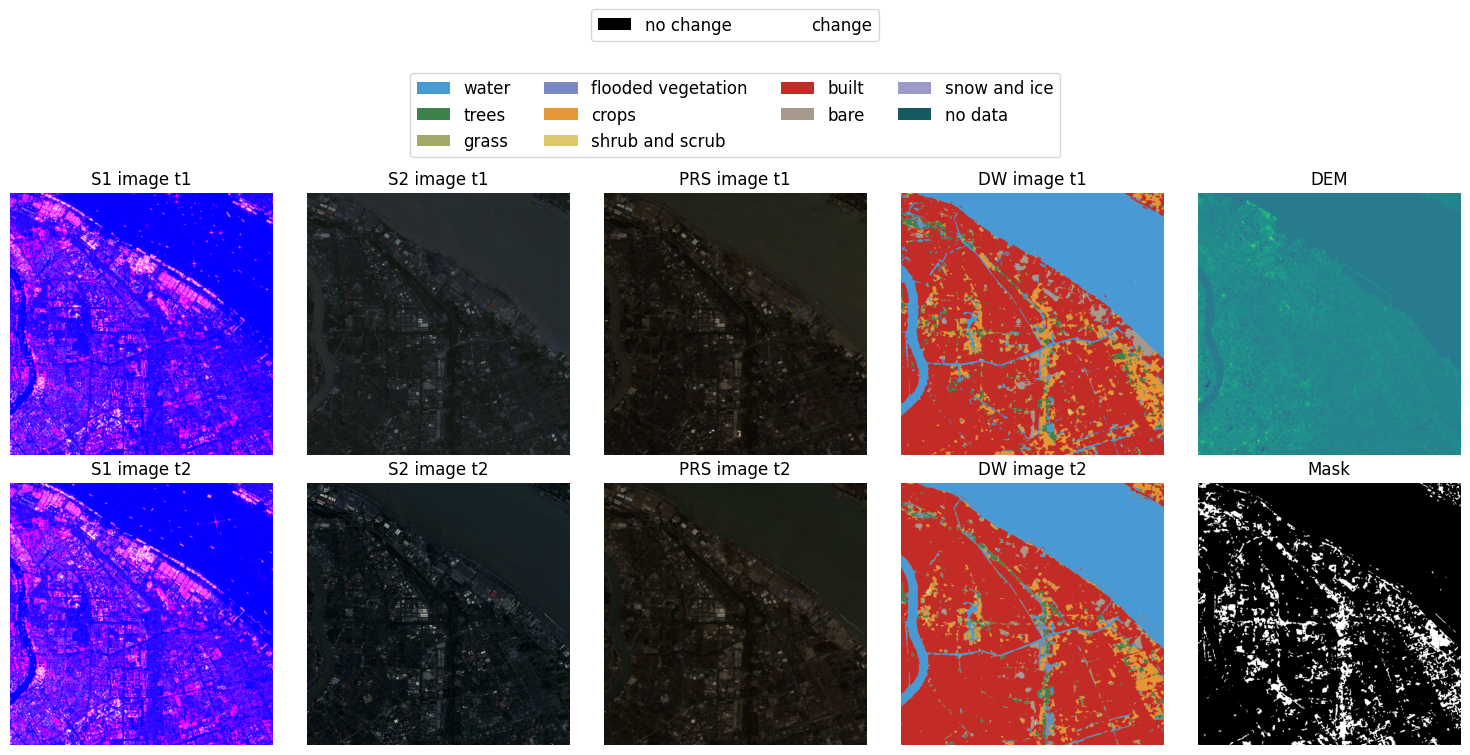

2026-03-09 08:49:47,932 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:49:48,138 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:49:48,311 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:49:48,472 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


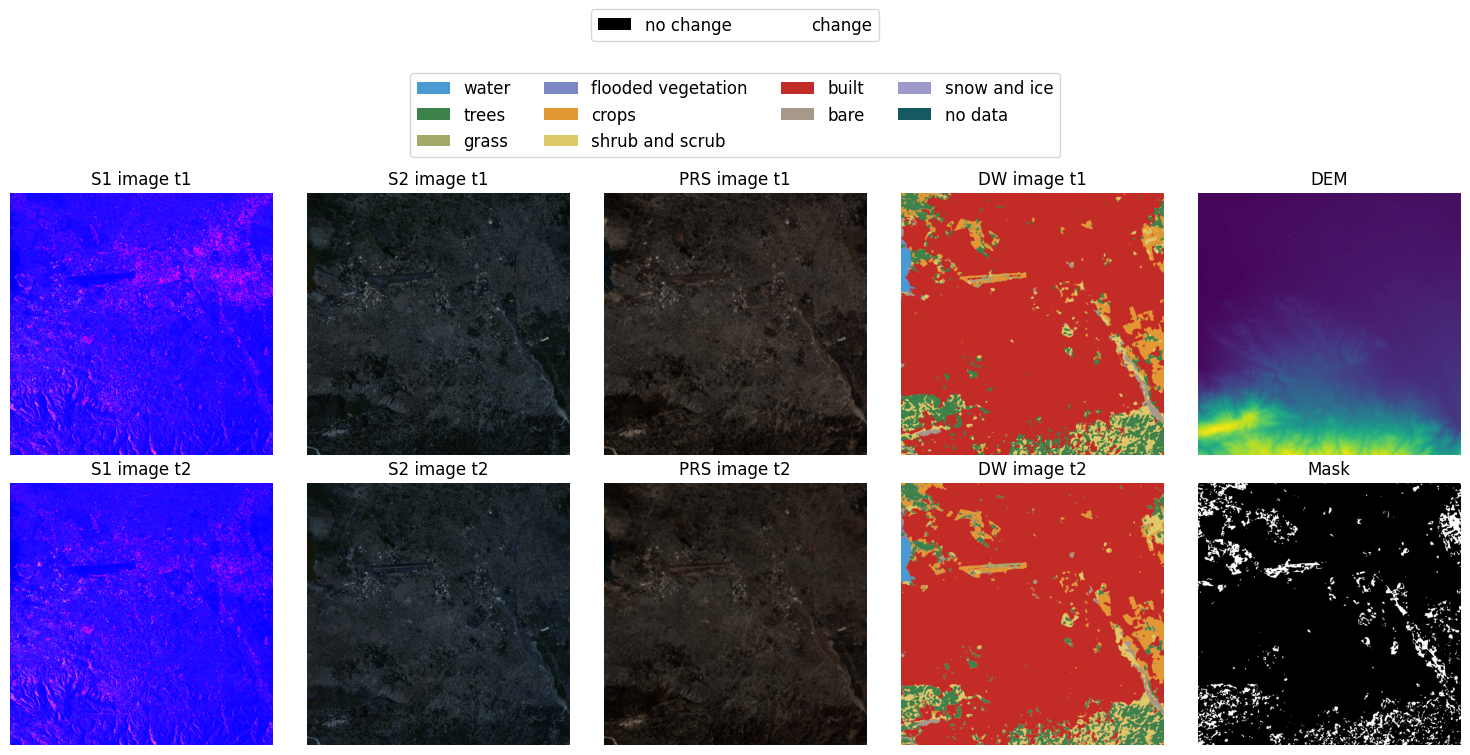

2026-03-09 08:50:38,355 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:50:38,385 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:50:38,437 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 08:50:38,644 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


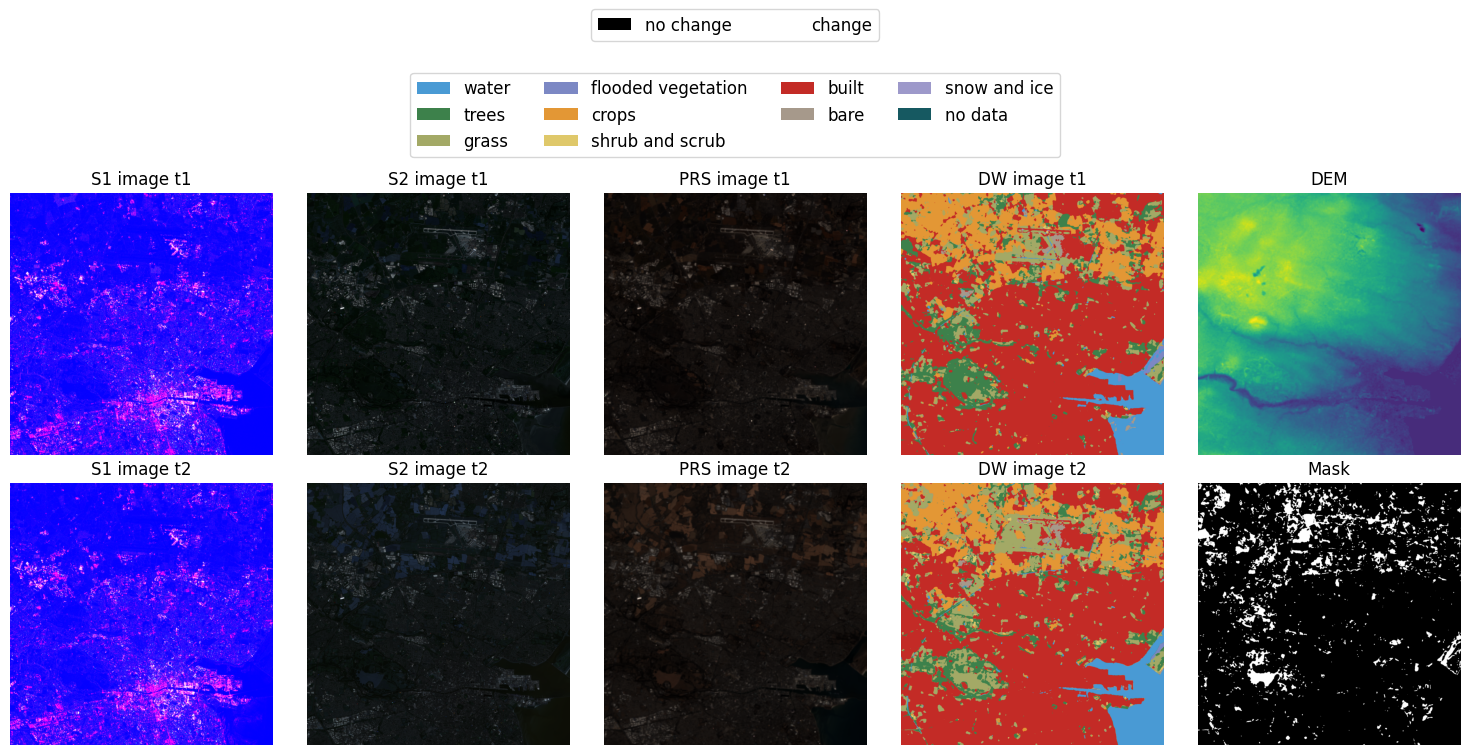

In [41]:
dataset.show_image(1);
dataset.show_image(15);
dataset.show_image(22);

In [7]:
dataset.data_distribution_table()

,Number of pixels
no change,143075605.0
change,22075115.0


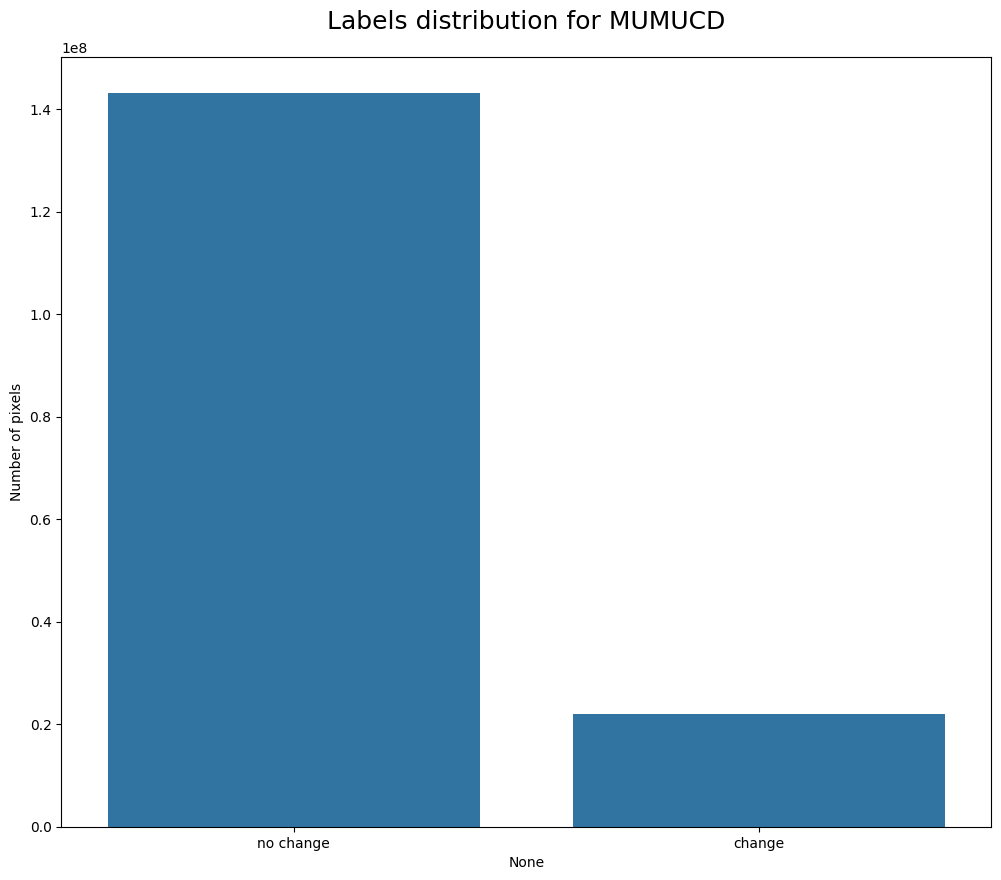

In [8]:
dataset.data_distribution_barchart();

## Load training and test data

In [51]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/mumucd/",
    "mode": "train",
    "imagery": "s2",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = MUMUCDDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/mumucd/",
    "mode": "val",
    "imagery": "s2",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = MUMUCDDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(42, 14)

## Create the model

In [52]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/mumucd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [53]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-03-09 08:54:52,222 INFO Starting training.
training: 100%|██████████| 11/11 [03:16<00:00, 17.89s/it]
2026-03-09 08:58:09,072 INFO epoch: 1, loss:  0.26956
testing on train set: 100%|██████████| 11/11 [03:12<00:00, 17.46s/it]
2026-03-09 09:01:22,254 INFO Accuracy:0.8340339660644531, Accuracy per Class:[0.69726199 0.97080594], Precision Micro:0.6972738251463798, Precision Macro:0.3486369125731899, Precision Weighted:0.669252958704213, Precision per Class:[0.69727383 0.        ], Recall Micro:0.9597846781198943, Recall Macro:0.49998488996245416, Recall Weighted:0.9597846781198943, Recall per Class:[0.99996978 0.        ], F1_score Micro:0.8077357950976407, F1_score Macro:0.41081477720444126, F1_score Weighted:0.7886112893045024, F1_score per Class:[0.82162955 0.        ], IOU:0.6774805381025352, IOU mean:0.34862956614493223, IOU per Class:[0.69725913 0.        ]
training: 100%|██████████| 11/11 [03:24<00:00, 18.55s/it]
2026-03-09 09:04:46,323 INFO epoch: 2, loss:  0.25328
testing on 

## Predictions

2026-03-09 15:49:04,442 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/mumucd/checkpoint.pth.tar
2026-03-09 15:49:04,788 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/mumucd/checkpoint.pth.tar at epoch 51


14


2026-03-09 15:50:44,140 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 15:50:44,189 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


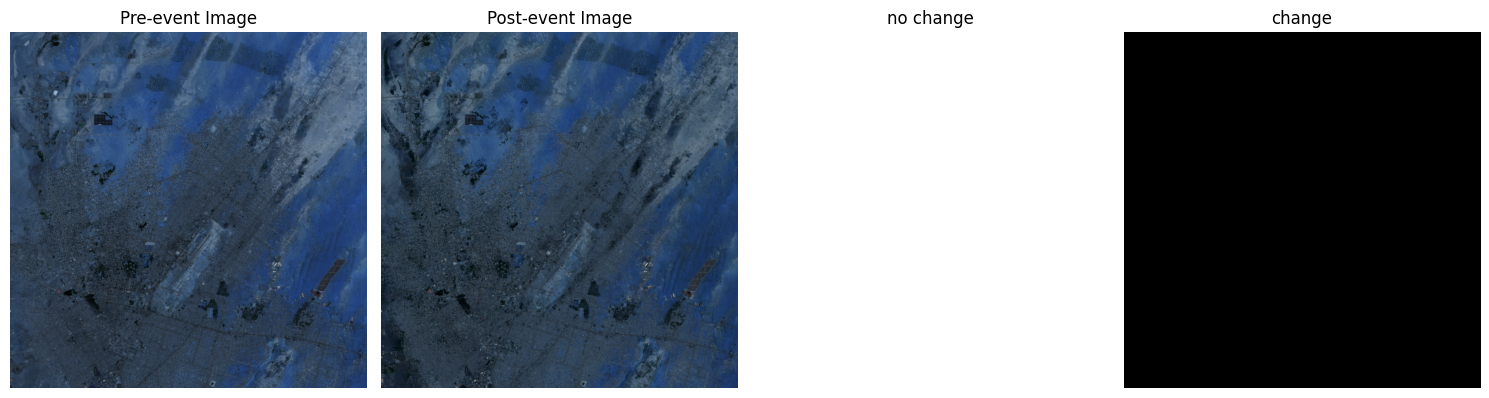

2026-03-09 15:52:27,232 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2026-03-09 15:52:27,280 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


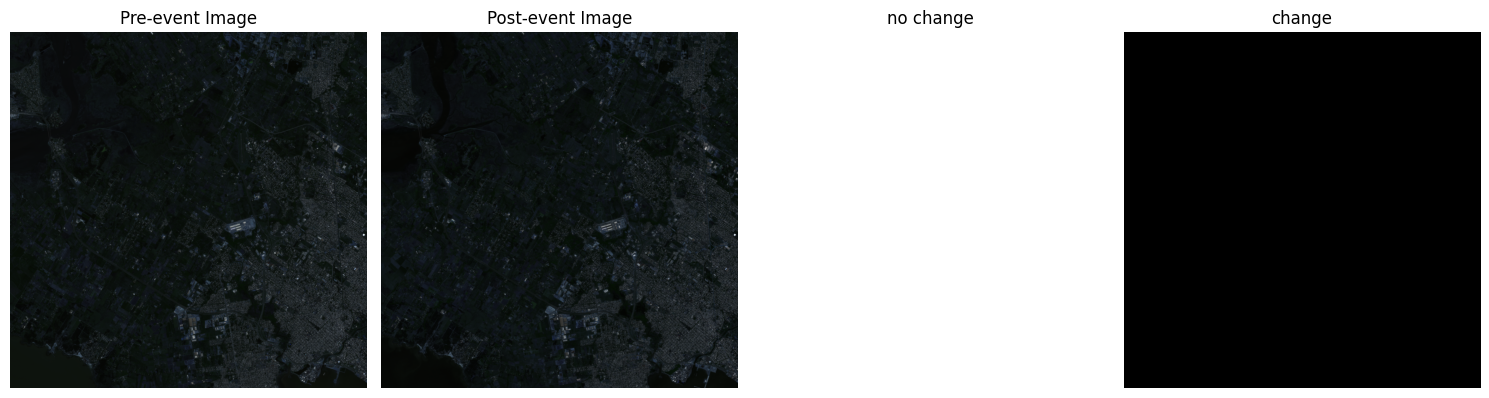

In [54]:
model_path = "/home/dragik/data/FAIR_EO/experiments/mumucd/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/mumucd/",
    "mode": "test",
    "imagery": "s2",
    "selection": "rgb"
}
test_dataset = MUMUCDDataset(test_dataset_config)
print(len(test_dataset))

image1 = test_dataset[0][0][0]
image2 = test_dataset[0][0][1]
fig = model.predict_masks(image1, image2, labels, transform)

image1 = test_dataset[10][0][0]
image2 = test_dataset[10][0][1]
fig = model.predict_masks(image1, image2, labels, transform)